# Example of the aitlas toolbox in the context of image classification

The data consists of a single pixel value for each S2 band, for each time step (365 days). To each S2 pixel value time series is associated a crop type label.

## Import the required packages

In [ ]:
from aitlas.datasets import EuroCropsMLDataset
from aitlas.utils import image_loader
from aitlas.models import LSTM
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Inspect the data

In [ ]:
dataset_config = {
    "data_dir" : "./data/eurocropsml/raw_data/Estonia.parquet",
}
dataset = EuroCropsMLDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 176055


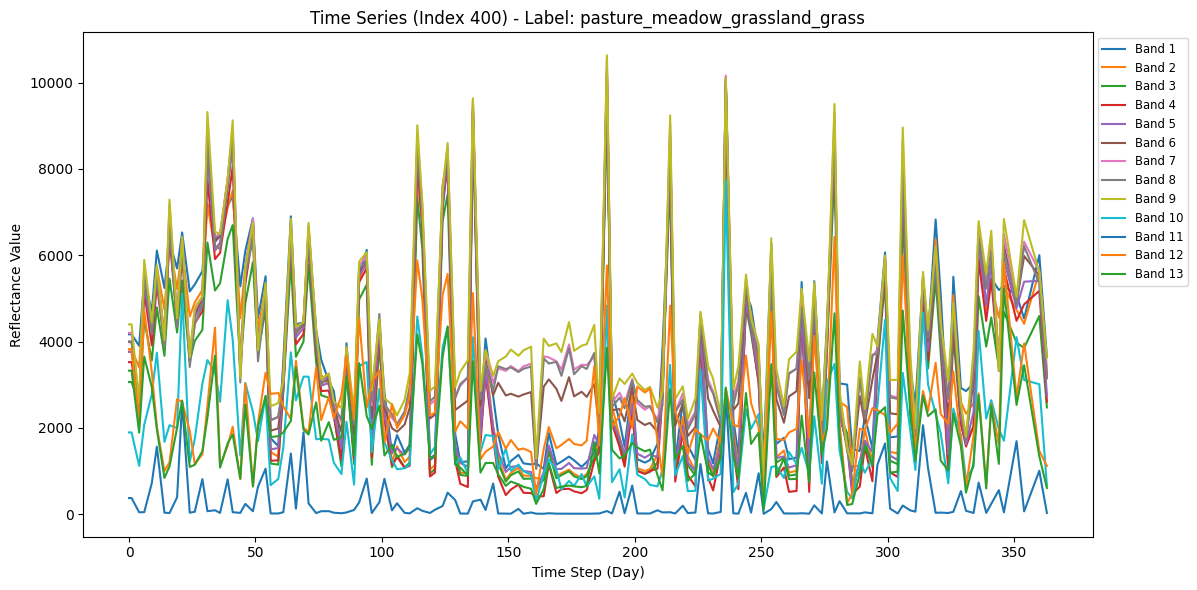

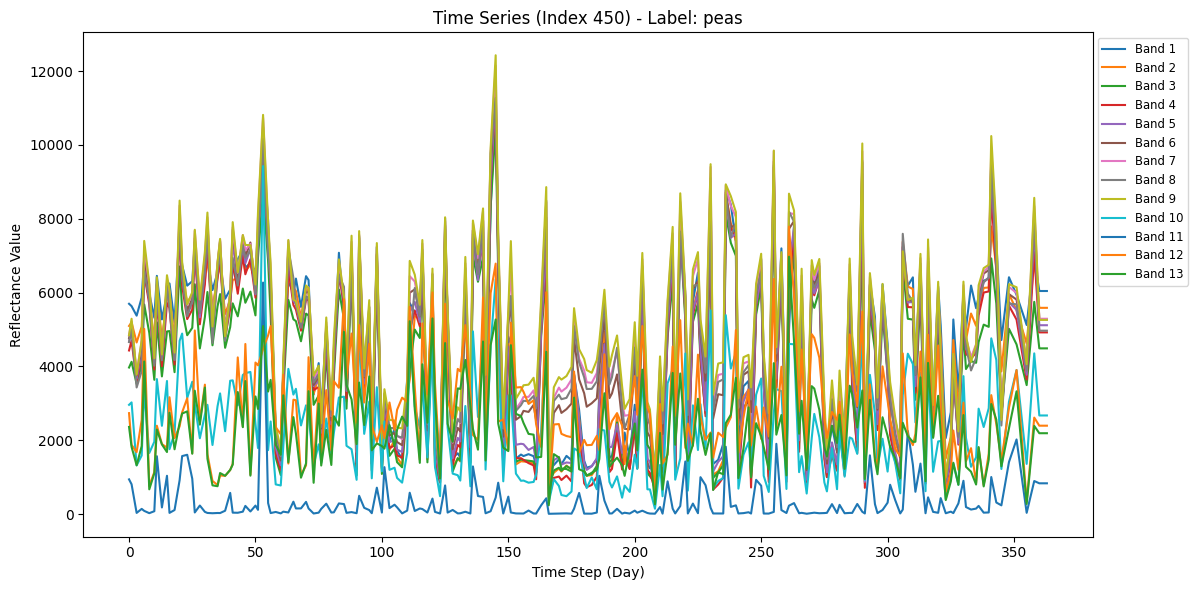

In [6]:
dataset.show_timeseries(index=400)
dataset.show_timeseries(index=450);

In [20]:
dataset.data_distribution_table()

,Label,Count
0,pasture_meadow_grassland_grass,84104
1,winter_common_soft_wheat,13723
2,legumes_harvested_green,13151
3,spring_barley,10737
4,oats,6911
...,...,...
122,hazelnuts_hazel,1
123,lentils,1
124,primrose,1
125,currants,1


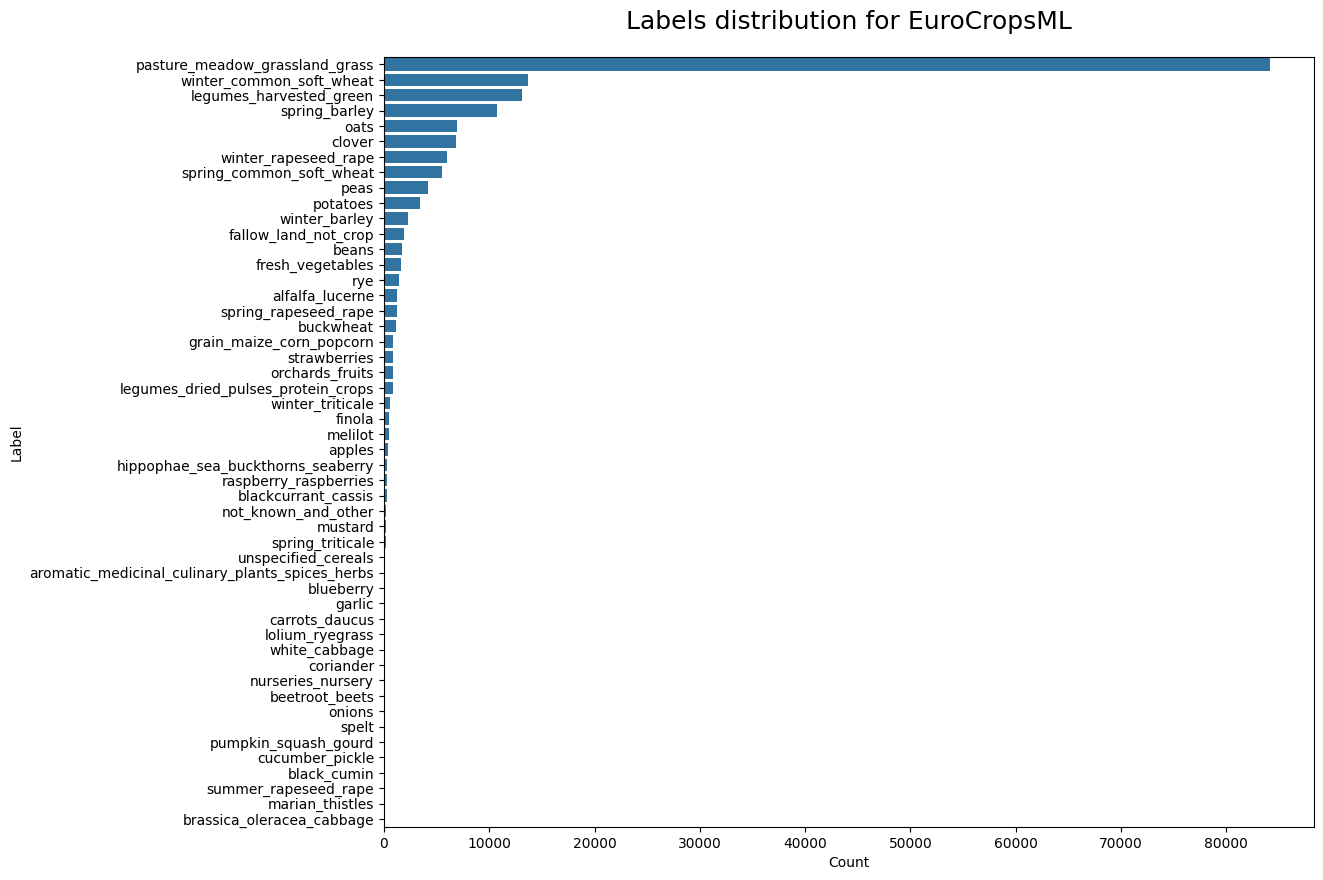

In [38]:
dataset.data_distribution_barchart();

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/eurocropsml/raw_data/Latvia.parquet"
}
train_dataset = EuroCropsMLDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/eurocropsml/raw_data/Estonia.parquet"
}
test_dataset = EuroCropsMLDataset(test_dataset_config)

print(len(train_dataset),len(test_dataset))

431174 176055


## Create the model ##

In [ ]:
epochs = 2
model_directory = "./data/experiments/eurocropsml/"
model_config = {
                "input_dim": 13,
                "num_classes": 176,
                "learning_rate": 0.00988,
                "weight_decay" : 0.000000526,
                "num_layers" : 4,
                "hidden_dims" : 128,
                "dropout" : 0.5713,
                "metrics":["accuracy","f1_score", "kappa"]
            }
model = LSTM(model_config)
model.prepare()

## Start the training

In [7]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=test_dataset,
    run_id='1',
)

2026-03-05 13:52:31,504 INFO Starting training.
training: 100%|██████████| 26949/26949 [19:14<00:00, 23.34it/s]
2026-03-05 14:11:46,117 INFO epoch: 1, time: 1155, loss:  1.41096
testing on train set: 100%|██████████| 26949/26949 [15:28<00:00, 29.02it/s] 
2026-03-05 14:27:14,721 INFO Accuracy:0.7099477241206567, F1_score Micro:0.7099477241206562, F1_score Macro:0.03710548542747397, F1_score Weighted:0.6708283288943816, F1_score per Class:[0.         0.83232779 0.43104752 0.10755085 0.         0.
 0.13110754 0.43168323 0.57936073 0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.02780005 0.         0.
 0.         0.13232035 0.         0.27677281 0.         0.
 0.         0.93882501 0.         0.39666358 0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.   

1.096084333336244